In [11]:
# 0. 필요한 라이브러리
import cv2
import mediapipe as mp
import numpy as np
import matplotlib.pyplot as plt
import csv
import time

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("성능 평가 라이브러리 준비 완료!")

성능 평가 라이브러리 준비 완료!


In [12]:
from pathlib import Path

print("현재 작업 폴더:", Path.cwd())

csv_path = Path.cwd() / "pikipick_baseline_results.csv"

print("CSV 파일 존재 여부:", csv_path.exists())

현재 작업 폴더: c:\Users\mbc\Desktop\엄정희 가위바위보\mediapipe_training
CSV 파일 존재 여부: True


In [13]:
# ============================================================
# 1. MediaPipe Gesture Recognizer 모델 파일 확인
# 목적: 성능 평가에 사용할 모델이 정상적으로 저장되어 있는지 확인
# ============================================================

# 1) 파일 및 폴더 경로를 관리하는 라이브러리
from pathlib import Path

# 2) 현재 Jupyter Notebook이 실행되는 폴더 확인
current_path = Path.cwd()

print("현재 작업 폴더:", current_path)

# 3) MediaPipe 모델 파일 경로 설정
# mediapipe_training 폴더의 상위 폴더로 이동한 뒤
# mediapipe_hand 폴더에서 모델 파일을 찾음
MODEL_PATH = (
    current_path.parent
    / "mediapipe_hand"
    / "gesture_recognizer.task"
)

# 4) 모델 파일이 실제로 존재하는지 확인
print("모델 파일 경로:", MODEL_PATH)
print("모델 파일 존재 여부:", MODEL_PATH.is_file())

# 5) 모델 파일이 없는 경우 오류 발생
if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"MediaPipe 모델 파일을 찾을 수 없습니다: {MODEL_PATH}"
    )

# 6) 정상 확인 메시지
print("MediaPipe 모델 파일 확인 완료!")

현재 작업 폴더: c:\Users\mbc\Desktop\엄정희 가위바위보\mediapipe_training
모델 파일 경로: c:\Users\mbc\Desktop\엄정희 가위바위보\mediapipe_hand\gesture_recognizer.task
모델 파일 존재 여부: True
MediaPipe 모델 파일 확인 완료!


In [14]:

# ============================================================
# 2. MediaPipe 가위바위보 성능 평가 데이터 수집
# 목적: 실제 손동작과 모델 예측 결과를 비교할 데이터 생성
# ============================================================

# 0. 필요한 라이브러리
import cv2
import mediapipe as mp
import time
import csv

from pathlib import Path


# 1. 모델 파일 경로
# 앞 단계에서 확인한 모델 파일 사용
MODEL_PATH = (
    Path.cwd().parent
    / "mediapipe_hand"
    / "gesture_recognizer.task"
)

if not MODEL_PATH.is_file():
    raise FileNotFoundError(f"모델 파일 없음: {MODEL_PATH}")


# 2. MediaPipe Gesture Recognizer 설정
BaseOptions = mp.tasks.BaseOptions
GestureRecognizer = mp.tasks.vision.GestureRecognizer
GestureRecognizerOptions = mp.tasks.vision.GestureRecognizerOptions
RunningMode = mp.tasks.vision.RunningMode

options = GestureRecognizerOptions(
    base_options=BaseOptions(
        model_asset_buffer=MODEL_PATH.read_bytes()
    ),
    running_mode=RunningMode.VIDEO,
    num_hands=1
)


# 3. MediaPipe 결과를 가위바위보 이름으로 변환
RPS_MAP = {
    "Closed_Fist": "ROCK",
    "Victory": "SCISSORS",
    "Open_Palm": "PAPER"
}


# 4. 키보드 입력을 실제 정답으로 지정
# 카메라 화면을 클릭한 후 숫자 키를 누르면 기록됨
KEY_MAP = {
    ord("1"): "ROCK",
    ord("2"): "SCISSORS",
    ord("3"): "PAPER"
}


# 5. 평가 데이터 저장 리스트
records = []

# 5. 기존 CSV 데이터 불러오기
import csv
from pathlib import Path

# 기존 평가 CSV 파일 경로
output_path = Path.cwd() / "pikipick_baseline_results.csv"

# 기존 데이터 저장 리스트
records = []

# 기존 CSV 파일이 있으면 데이터 불러오기
if output_path.is_file():
    with output_path.open(
        "r", encoding="utf-8-sig", newline=""
    ) as f:
        records = list(csv.DictReader(f))

print("기존 데이터 수:", len(records))


# 6. 웹캠 실행
cap = cv2.VideoCapture(0, cv2.CAP_DSHOW)

if not cap.isOpened():
    raise RuntimeError("웹캠 연결 실패!")

cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)

print("PIKIPICK 성능 평가 데이터 수집 시작!")
print("1 = 바위 / 2 = 가위 / 3 = 보")
print("Q = 평가 종료 및 CSV 저장")


# 7. 실시간 모델 예측 및 평가 데이터 수집
try:
    with GestureRecognizer.create_from_options(
        options
    ) as recognizer:

        start_time = time.monotonic()
        last_timestamp = -1

        while True:

            # 8. 웹캠 프레임 읽기
            success, frame = cap.read()

            if not success:
                print("카메라 영상 읽기 실패")
                break

            # 화면 좌우 반전
            frame = cv2.flip(frame, 1)

            # 9. OpenCV BGR 영상을 RGB로 변환
            rgb = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2RGB
            )

            mp_image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=rgb
            )

            # 10. VIDEO 모드 타임스탬프
            timestamp = int(
                (time.monotonic() - start_time) * 1000
            )

            timestamp = max(
                timestamp,
                last_timestamp + 1
            )

            last_timestamp = timestamp

            # 11. MediaPipe 손동작 예측
            result = recognizer.recognize_for_video(
                mp_image,
                timestamp
            )

            # 손 관절 검출 여부
            hand_detected = bool(result.hand_landmarks)

            # 기본 예측값
            model_name = "None"
            confidence = 0.0
            prediction = "UNKNOWN"

            # 12. 모델 예측 결과 추출
            if result.gestures and result.gestures[0]:

                category = result.gestures[0][0]

                model_name = category.category_name
                confidence = category.score

                prediction = RPS_MAP.get(
                    model_name,
                    "UNKNOWN"
                )

            # 13. 카메라 화면에 예측 결과 표시
            cv2.putText(
                frame,
                f"Prediction: {prediction}",
                (15, 35),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.8,
                (0, 255, 255),
                2
            )

            cv2.putText(
                frame,
                f"Model: {model_name} ({confidence:.2f})",
                (15, 70),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255, 255, 255),
                2
            )

            cv2.putText(
                frame,
                f"Saved Samples: {len(records)}",
                (15, 105),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (255, 255, 255),
                2
            )

            cv2.imshow(
                "PIKIPICK - Data Collection",
                frame
            )

            # 14. 키보드 입력 확인
            key = cv2.waitKey(1) & 0xFF

            # 숫자 키를 누르면 현재 프레임 기록
            if key in KEY_MAP:

                true_label = KEY_MAP[key]

                records.append({
                    "true_label": true_label,
                    "prediction": prediction,
                    "model_name": model_name,
                    "confidence": confidence,
                    "hand_detected": int(hand_detected),
                    "timestamp_ms": timestamp
                })

                print(
                    f"[{len(records)}] "
                    f"정답: {true_label} | "
                    f"예측: {prediction} | "
                    f"손 검출: {hand_detected}"
                )

            # Q 키로 종료
            elif key == ord("q"):
                break

finally:
    # 15. 웹캠과 화면 종료
    cap.release()
    cv2.destroyAllWindows()


# 16. 수집한 데이터를 CSV 파일로 저장
output_path = (
    Path.cwd() / "pikipick_baseline_results.csv"
)

with output_path.open(
    "w",
    newline="",
    encoding="utf-8-sig"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=[
            "true_label",
            "prediction",
            "model_name",
            "confidence",
            "hand_detected",
            "timestamp_ms"
        ]
    )

    writer.writeheader()
    writer.writerows(records)


# 17. 수집 결과 출력
print("=" * 45)
print("PIKIPICK 데이터 수집 완료!")
print("총 데이터 수:", len(records))
print("CSV 저장 위치:", output_path)
print("=" * 45)


기존 데이터 수: 156
PIKIPICK 성능 평가 데이터 수집 시작!
1 = 바위 / 2 = 가위 / 3 = 보
Q = 평가 종료 및 CSV 저장
[157] 정답: SCISSORS | 예측: UNKNOWN | 손 검출: True
[158] 정답: SCISSORS | 예측: UNKNOWN | 손 검출: True
[159] 정답: SCISSORS | 예측: UNKNOWN | 손 검출: True
[160] 정답: SCISSORS | 예측: UNKNOWN | 손 검출: True
[161] 정답: SCISSORS | 예측: UNKNOWN | 손 검출: True
[162] 정답: SCISSORS | 예측: UNKNOWN | 손 검출: True
[163] 정답: SCISSORS | 예측: UNKNOWN | 손 검출: True
[164] 정답: SCISSORS | 예측: SCISSORS | 손 검출: True
[165] 정답: SCISSORS | 예측: UNKNOWN | 손 검출: True
[166] 정답: SCISSORS | 예측: UNKNOWN | 손 검출: True
[167] 정답: SCISSORS | 예측: UNKNOWN | 손 검출: True
PIKIPICK 데이터 수집 완료!
총 데이터 수: 167
CSV 저장 위치: c:\Users\mbc\Desktop\엄정희 가위바위보\mediapipe_training\pikipick_baseline_results.csv


In [15]:
# 18. 성능 평가 CSV 생성 확인
from pathlib import Path

csv_path = Path.cwd() / "pikipick_baseline_results.csv"

print("CSV 존재 여부:", csv_path.exists())
print("CSV 저장 경로:", csv_path)

CSV 존재 여부: True
CSV 저장 경로: c:\Users\mbc\Desktop\엄정희 가위바위보\mediapipe_training\pikipick_baseline_results.csv


PIKIPICK - MediaPipe 기본 모델 성능
평가 샘플 수 : 167
손 검출률    : 100.00%
Accuracy     : 23.35%

[Classification Report]
              precision    recall  f1-score   support

        ROCK     1.0000    0.1905    0.3200        21
    SCISSORS     1.0000    0.1250    0.2222       104
       PAPER     1.0000    0.5238    0.6875        42

   micro avg     1.0000    0.2335    0.3786       167
   macro avg     1.0000    0.2798    0.4099       167
weighted avg     1.0000    0.2335    0.3515       167



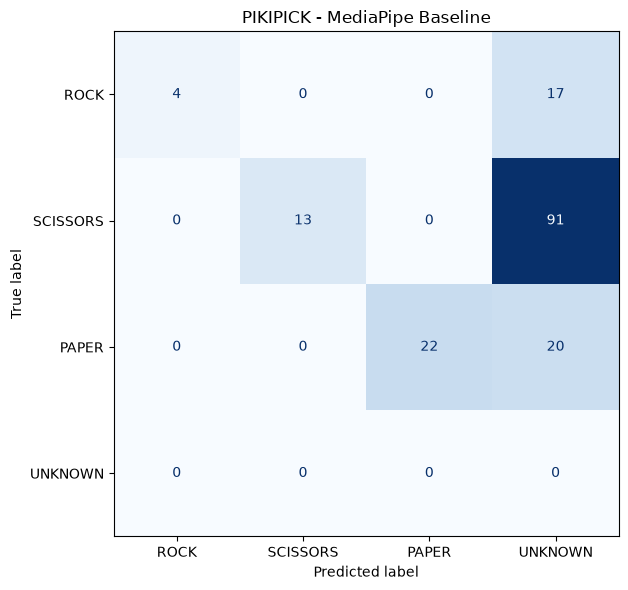


[가위 인식 분석]
가위 평가 수: 104
가위 인식 성공: 13
UNKNOWN 예측: 91
가위 재현율: 12.50%


In [16]:

# 10. 저장된 CSV 불러오기
csv_path = Path.cwd() / "pikipick_baseline_results.csv"

with csv_path.open(
    "r", encoding="utf-8-sig", newline=""
) as f:
    records = list(csv.DictReader(f))

if not records:
    raise ValueError("평가 데이터가 없습니다.")

# 실제 정답과 모델 예측
y_true = [r["true_label"] for r in records]
y_pred = [r["prediction"] for r in records]

labels = ["ROCK", "SCISSORS", "PAPER"]
matrix_labels = labels + ["UNKNOWN"]

# 11. 정확도
accuracy = accuracy_score(y_true, y_pred)

# 12. 손 검출률
detected_count = sum(
    int(r["hand_detected"]) for r in records
)
detection_rate = detected_count / len(records)

print("=" * 45)
print("PIKIPICK - MediaPipe 기본 모델 성능")
print("=" * 45)
print(f"평가 샘플 수 : {len(records)}")
print(f"손 검출률    : {detection_rate * 100:.2f}%")
print(f"Accuracy     : {accuracy * 100:.2f}%")

# 13. 클래스별 성능
# UNKNOWN 예측은 틀린 예측으로 반영
print("\n[Classification Report]")

print(
    classification_report(
        y_true,
        y_pred,
        labels=labels,
        zero_division=0,
        digits=4
    )
)

# 14. 혼동행렬
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=matrix_labels
)

fig, ax = plt.subplots(figsize=(8, 6))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=matrix_labels
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("PIKIPICK - MediaPipe Baseline")
plt.tight_layout()
plt.show()

# 15. 가위 인식 결과 별도 분석
scissors_rows = [
    r for r in records
    if r["true_label"] == "SCISSORS"
]

if scissors_rows:
    scissors_correct = sum(
        r["prediction"] == "SCISSORS"
        for r in scissors_rows
    )

    scissors_unknown = sum(
        r["prediction"] == "UNKNOWN"
        for r in scissors_rows
    )

    print("\n[가위 인식 분석]")
    print("가위 평가 수:", len(scissors_rows))
    print("가위 인식 성공:", scissors_correct)
    print("UNKNOWN 예측:", scissors_unknown)
    print(
        "가위 재현율:",
        f"{scissors_correct / len(scissors_rows) * 100:.2f}%"
    )
